# 6A: 5'-UTR CGG Scatterplot

In [1]:
# initial data loading and package import
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe

try:
    from adjustText import adjust_text
except Exception:
    adjust_text = None

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text as text
PALETTE = {"Catalog": "#195CAC", "Pathogenic": "#EB282D"}

lps=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
annotations=pd.read_csv('assets/genicRegionAnnotations_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','region'])
# function to convert motifs to their simplest rotational form with reverse complements
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))
# sum up number of unique lengths per locus
lps['uniqueLengths2']=lps.groupby('TRID')['uniqueLengths'].transform(sum)
# get most common lps motif per locus
lps=lps.sort_values(by='N_motif',ascending=False).drop_duplicates(subset='TRID',keep='first').sort_values(by='TRID',ascending=True)
lps['simpleMotif']=lps.loc[:,'LPS_Motif'].apply(simplest_motif)

# calculate the 95th percentile of stdev for trinucleotides 
lps['motifLen']=lps.loc[:,'simpleMotif'].str.len()
lps=lps.loc[lps['motifLen']==3,:]
ninetyFifth=lps.loc[:,'std'].quantile(0.95)

# filter down to only 5'UTR CCGs
lps2=lps.loc[lps['simpleMotif']=='CCG',:]
df=lps2.loc[lps2['TRID'].isin(annotations.loc[annotations['region']=='UTR_5','TRID'].values),:]

# Mark disease-associated loci
pathogenicAnnotated=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
TRToGeneName=pd.read_csv('assets/TR_to_gene_name_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','geneName'])

df['Status']='Catalog'
df.loc[df['TRID'].isin(pathogenicAnnotated['TRID'].values),'Status']='Pathogenic'
df=df.merge(TRToGeneName,how='inner',on='TRID')
counts = df['Status'].value_counts().to_dict()



C:\Users\Matt\AppData\Local\Temp\ipykernel_89956\1960116081.py:48: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  lps['uniqueLengths2']=lps.groupby('TRID')['uniqueLengths'].transform(sum)
C:\Users\Matt\AppData\Local\Temp\ipykernel_89956\1960116081.py:66: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Status']='Catalog'


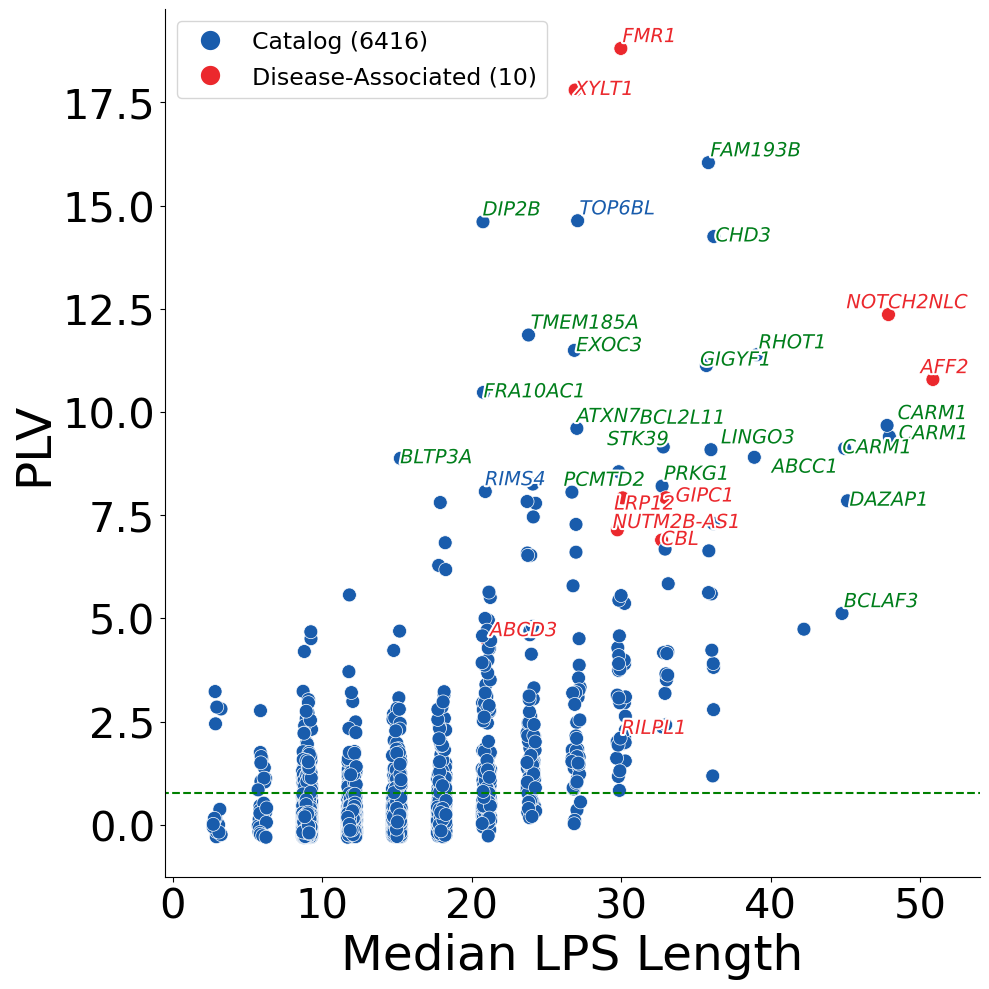

In [2]:
# plot
# Add light uniform jitter (±0.3) so points don't stack perfectly.
SEED = 7       # set to None for non‑deterministic
JITTER = 0.3   # half‑width of the jitter window (±JITTER)

rng = np.random.default_rng(SEED)

def add_jitter(series: pd.Series, scale: float = JITTER) -> pd.Series:
    return series.astype(float) + rng.uniform(-scale, scale, size=series.shape[0])

# Drop Catalog entries for genes that also have a Pathogenic entry (removes same-gene duplicates)
pathogenic_genes = set(df.loc[df['Status'] == 'Pathogenic', 'geneName'])
plot_df = df[~((df['Status'] == 'Catalog') & (df['geneName'].isin(pathogenic_genes)))].copy()

# jittered copies used only for plotting
x_col = "50thPercentile"
y_col = "std"

plot_df[f"{x_col}_j"] = add_jitter(plot_df[x_col])
plot_df[f"{y_col}_j"] = add_jitter(plot_df[y_col])

# Scatter plot
fig, ax = plt.subplots(figsize=(10, 10))

# color per Status, default gray if unknown
colors = plot_df["Status"].map(PALETTE).fillna("#666666")

ax.scatter(
    plot_df[f"{x_col}_j"], plot_df[f"{y_col}_j"],
    s=100, c=colors, edgecolors="white", linewidths=0.5,
)

# selective labels: always label Pathogenic; also large x or y
LABEL_X = 45.0
LABEL_Y = 8.0
mask = (plot_df["Status"] == "Pathogenic") | (plot_df[x_col] >= LABEL_X) | (plot_df[y_col] >= LABEL_Y)
validationSetCandidates=['PRKG1', 'FRA10AC1', 'DIP2B', 'ELF1', 'ELF1', 'ABCC1', 'RHOT1',
       'CHD3', 'ASXL3', 'CARM1', 'CARM1', 'CARM1', 'DAZAP1', 'LINGO3',
       'BCL2L11', 'STK39', 'PCMTD2', 'ATXN7', 'FAM193B', 'EXOC3',
       'BLTP3A', 'GIGYF1', 'TMEM185A', 'BCLAF3']
texts = []
xs, ys = [], []
for _, row in plot_df.loc[mask].iterrows():
    markerColor=PALETTE.get(row["Status"], "#222222")
    if row.get("geneName", "") in validationSetCandidates:
        markerColor="#007E1B"
    txt = ax.text(
        row[f"{x_col}_j"], row[f"{y_col}_j"], str(row.get("geneName", "")),
        fontsize=14, color=markerColor, style="italic",
        path_effects=[pe.withStroke(linewidth=3, foreground="white")],
    )
    texts.append(txt)
    xs.append(row[f"{x_col}_j"])
    ys.append(row[f"{y_col}_j"])

adjust_text(
    texts, x=xs, y=ys,
    #arrowprops=dict(arrowstyle='-', color='gray', lw=0.8),
    force_text=(2, 2),    # how strongly labels repel each other
    force_points=(0.2, 0.2),  # how strongly labels are repelled from data points
    expand=(0.9, 0.6),    # slight bbox expansion for overlap detection
    lim=2000,             # more iterations to reach convergence
)

ax.set_xlabel("Median LPS Length", fontsize=35)
ax.set_ylabel("PLV", fontsize=35)
ax.tick_params(labelsize=30)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# legend with dynamic counts
counts = plot_df["Status"].value_counts().to_dict()
handles = [
    Line2D([0], [0], marker='o', color='w',
           label=f"Catalog ({counts.get('Catalog',0)})",
           markersize=15, markerfacecolor=PALETTE['Catalog'],
           markeredgecolor='white', markeredgewidth=1.1),
    Line2D([0], [0], marker='o', color='w',
           label=f"Disease‑Associated ({counts.get('Pathogenic',0)})",
           markersize=15, markerfacecolor=PALETTE['Pathogenic'],
           markeredgecolor='white', markeredgewidth=1.1)
]
ax.legend(handles=handles, loc='upper left', prop={'size': 17})

# dashed line representing the 95th percentile threshold
plt.plot([-3,60],[ninetyFifth,ninetyFifth],'g--')
plt.xlim([-0.5,54])

plt.tight_layout()
plt.savefig('figures/figure6A.svg')
plt.savefig('figures/Figure6A.png',dpi=600)

# 6A: Prioritization of FAM193B Sample

In [ ]:
%%bash
# FAM193B Case using ONT data
SAMPLEID="FAM193B_case"
repeat_catalog_nickname="TR-Explorer_v1.0.1"
repeat_catalog_nickname2="TR-Explorer_v1.0.1_AoUPhase1"
catalog_lps_stats="DiscoveryCohort_lpsPerMotifStats_trgt.TR_Explorer_1.0.1.txt.gz"
pathogenicTRID="5-177554489-177554531-CGC"
TRCaller="medaka"
bcftools query -f "${SAMPLEID}\t%ID\t[%TGT\t%SD{0}\t%SD{1}]" ${SAMPLEID}_${repeat_catalog_nickname}.medaka.vcf.gz > ${SAMPLEID}_${repeat_catalog_nickname}_medaka.txt
python prioritizeTRWithinSample.py --inputFile=${SAMPLEID}_${repeat_catalog_nickname}_medaka.txt --sampleID=${SAMPLEID} --comparisonCatalog=${catalog_lps_stats} --comparisonCatalogNickname=${repeat_catalog_nickname2} --pathogenicTRID=${pathogenicTRID} --TRCaller=${TRCaller}


c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


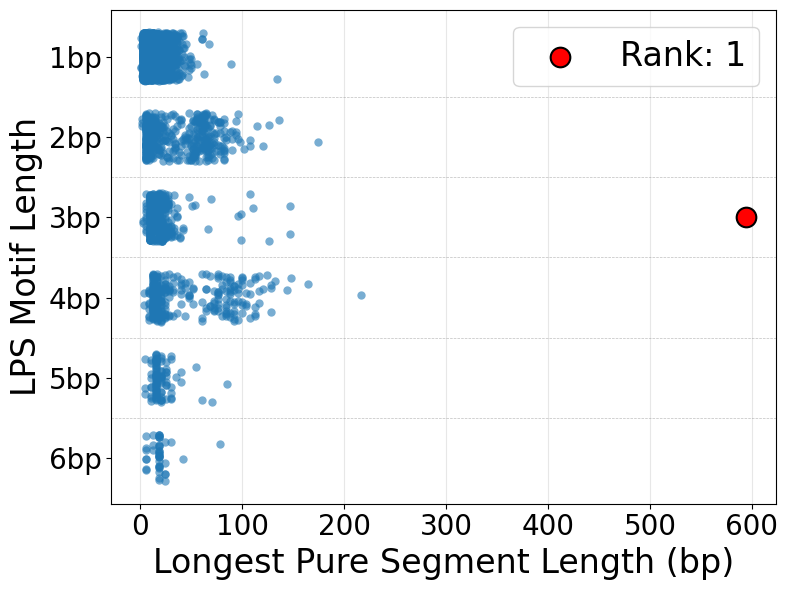

In [ ]:
# re-draw plot using a red circle
import pandas as pd
ranked=pd.read_csv('assets/outlierAnalyses/FAM193B/FAM193B_case_medaka.TR-Explorer_v1.0.1_AoUPhase1_prioritized_ranks.txt',sep='\t')
pathogenicTRID="5-177554489-177554531-CGC"

# Create the swimlane plot
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 6))

# Define motif categories
motif_categories = ['1bp', '2bp', '3bp', '4bp', '5bp', '6bp']
ranked=ranked.loc[ranked['Motif_Length_Category'].isin(motif_categories),:].reset_index(drop=True)

# get rank of pathogenic variant
overall_rank=ranked[ranked['TRID'] == pathogenicTRID].index.values[0]+1

# Create stripplot with categories
pathogenic_data = ranked[ranked['TRID'] == pathogenicTRID]
# drop the pathogenic entry from sample4_sorted
ranked2 = ranked[ranked['TRID'] != pathogenicTRID]
sns.stripplot(data=ranked2,
            y='Motif_Length_Category',
            x='LPS_Length',
            order=motif_categories,
            alpha=0.6,
            size=6,
            jitter=0.3)

# Add thin dashed grey lines between strips
for i in range(len(motif_categories) - 1):
    plt.axhline(y=i + 0.5, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)

# Highlight the pathogenic TRID if found
plt.scatter(pathogenic_data['LPS_Length'],
            pathogenic_data['Motif_Length_Category'],
            color='red',
            s=200,
            marker='o',
            zorder=5,
            label=f'Rank: {overall_rank}',
            edgecolors='black',
            linewidths=1.5)

plt.xlabel('Longest Pure Segment Length (bp)', fontsize=24)
plt.ylabel('LPS Motif Length', fontsize=24)
plt.tick_params(labelsize=20)
plt.legend(loc='upper right',fontsize=24)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

# Save the plot
plt.savefig("figures/Figure6B.png", dpi=600, bbox_inches='tight')
plt.savefig("figures/Figure6B.svg", bbox_inches='tight')

# 6C: Pedigrees

In [3]:
# There is no code for this panel

# 6D: FAM193B LPS Lengths

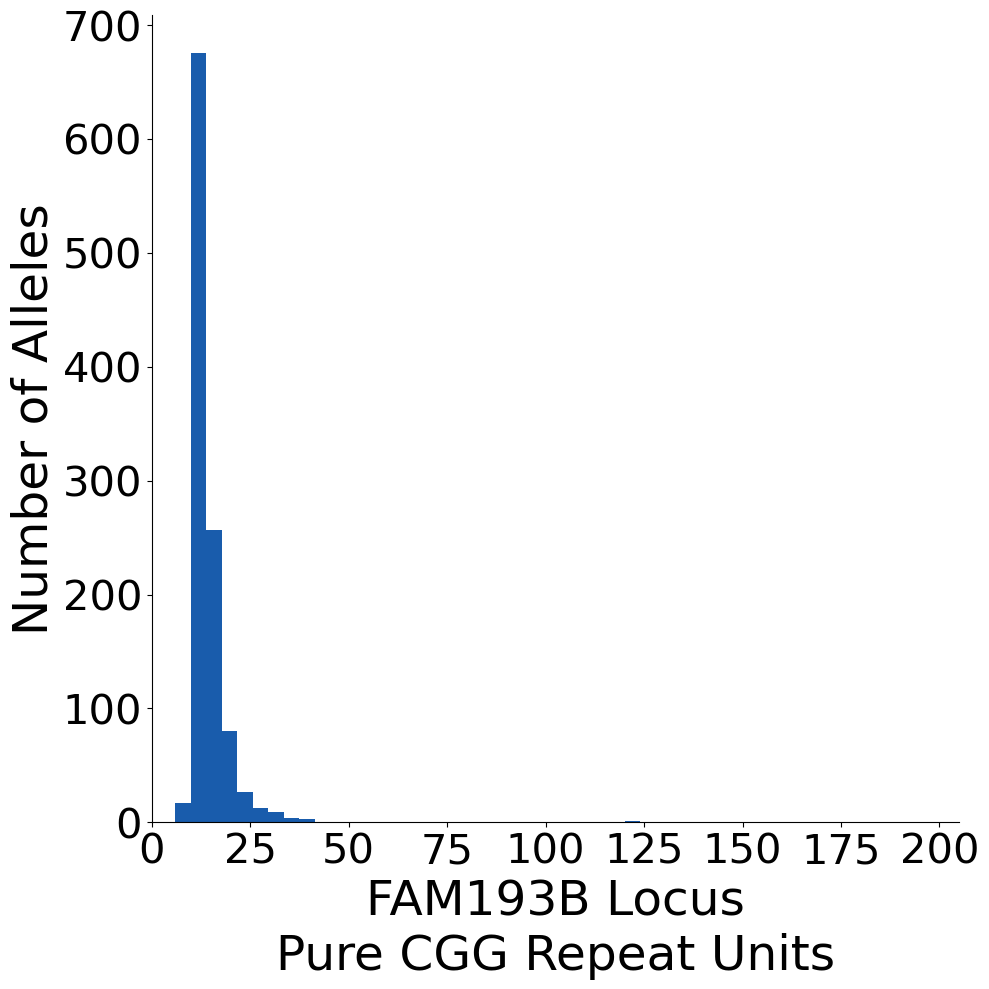

In [12]:
# initial data loading and package import
import pandas
import matplotlib.pyplot as plt
import matplotlib as mpl
alleleInfo=pandas.read_csv('assets/FAM193B_alleleInfo_noIDs.txt',sep='\t',low_memory=False,header=None,names=['TRID','Allele1','Allele2','LPSLength1','LPSMotif1','LPSLength2','LPSMotif2','Allele1_Len','Allele2_Len'])
lpsLengths=pandas.concat([alleleInfo.loc[:,['TRID','LPSLength1','LPSMotif1']].rename(columns={'LPSLength1':'LPSLength','LPSMotif1':'LPSMotif'}),
                          alleleInfo.loc[:,['TRID','LPSLength2','LPSMotif2']].rename(columns={'LPSLength2':'LPSLength','LPSMotif2':'LPSMotif'})],ignore_index=True)
# Select the LPSMotifs that are variations of 'CGG' and create a 'repeat unit' measure of the LPS length
lpsLengths2=lpsLengths.loc[lpsLengths['LPSMotif'].isin(['CCG','CGG','CGC','GCC']),:].reset_index(drop=True)
lpsLengths2['LPSLengthRU']=lpsLengths2.loc[:,'LPSLength']/3

# plot histogram of the distribution of CCG LPS values
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
fig, ax = plt.subplots(figsize=(10, 10))
plt.hist(lpsLengths2.loc[:,'LPSLengthRU'].values,color=colorPalette[5],bins=30)
plt.xlabel('FAM193B Locus\nPure CGG Repeat Units',fontsize=35)
plt.ylabel('Number of Alleles',fontsize=35)
plt.xticks(fontsize=30)
plt.xlim([0,205])
plt.yticks(fontsize=30)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/Figure6D.svg')
plt.savefig('figures/Figure6D.png',dpi=600)



# 6E: FAM193B Expression

In [11]:
# There is no code for this panel